# Red Wine Quality QC

**ML Zoomcamp 2026 — midterm project**

Predict, from a batch's lab analysis, the probability that the sensory panel will rate a red *Vinho Verde* wine as **good** (quality ≥ 7).

Contents:
1. Problem description
2. Data loading and preparation
3. Exploratory data analysis (EDA)
4. Validation framework

## 1. Problem description

**Context.** Before bottling, a winery's lab measures the physicochemical profile of each batch: acidity, sugar, sulfur dioxide, sulphates, alcohol and so on. The final quality grade comes from a sensory panel of trained tasters, which is slow and expensive.

**Problem.** Given the 11 lab values of a red Vinho Verde batch, estimate the probability that the panel will rate it **good** (quality ≥ 7 on a 0–10 scale). This is a **binary classification** problem.

**How the model is used.** A QC technician sends the lab values to a REST API and gets back `good_probability` and a yes/no flag. The winery uses this to:
- (a) prioritise which batches go to the full tasting panel or the premium line;
- (b) flag likely-mediocre batches early, while blending or adjustments are still possible.

**Who it is *not* for.** Consumers in a shop. They don't know a wine's volatile acidity or sulphates.

**Metric.** Only ~13.5% of wines are good, so the classes are imbalanced and **accuracy is misleading**: a model that always answers "not good" is already ~86% accurate. Instead:
- primary metric: **ROC AUC** (does not depend on a threshold);
- secondary metric: **PR AUC** (average precision), which focuses on the rare positive class.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split

%matplotlib inline
pd.set_option('display.max_columns', 20)
sns.set_theme(style='whitegrid')

def save(name):
    # save the current figure for the README
    plt.savefig(f'images/{name}.png', dpi=110, bbox_inches='tight')

## 2. Data loading and preparation

The dataset is the UCI *Wine Quality* data (Cortez et al., 2009), red wines only. The UCI file is separated by semicolons, while some copies elsewhere (e.g. Kaggle) use commas. `sep=None, engine='python'` lets pandas detect the separator, so either version works.

In [2]:
df = pd.read_csv('data/winequality-red.csv', sep=None, engine='python')
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
ph                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [4]:
print('shape:', df.shape)
df.isnull().sum()

shape: (1599, 12)


fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

All 12 columns are numeric (11 lab measurements plus the `quality` score), and there are **no missing values**, so no imputation is needed.

### 2.1 Duplicates

Each row should be a different wine sample. Let's check for rows that are exact copies of each other.

In [5]:
n_dup = df.duplicated().sum()
print(f'exact duplicate rows: {n_dup} ({n_dup / len(df):.1%})')
print(f'unique rows: {len(df.drop_duplicates())}')

exact duplicate rows: 240 (15.0%)
unique rows: 1359


In [6]:
# a few examples: every row that has at least one identical copy, sorted so copies sit together
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5


#### Why duplicates matter: leakage

If an identical row lands in both the training part and the validation part of a split, the model is validated partly on rows it has already seen. The score then looks better than it would on genuinely new batches.

To measure the effect, we run the same experiment twice, once on the raw data and once on the de-duplicated data. The experiment is a default random forest with stratified 5-fold cross-validation, repeated 3 times with different shuffles so the comparison isn't down to one lucky split.

*(The target `good` is defined properly in §2.2; here we only need it for the experiment.)*

In [7]:
features = [c for c in df.columns if c != 'quality']

def cv_auc(data):
    X = data[features]
    y = (data.quality >= 7).astype(int)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)
    rf = RandomForestClassifier(random_state=1, n_jobs=-1)
    return cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')

for name, data in [('raw (with duplicates)', df), ('de-duplicated', df.drop_duplicates())]:
    scores = cv_auc(data)
    print(f'{name:22s} ROC AUC = {scores.mean():.3f} ± {scores.std():.3f}')

raw (with duplicates)  ROC AUC = 0.917 ± 0.036


de-duplicated          ROC AUC = 0.872 ± 0.033


In [8]:
# How often does a validation row have an identical copy in training? (one 5-fold split on the raw data)
from sklearn.model_selection import StratifiedKFold

y_raw = (df.quality >= 7).astype(int)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
shares = []
for tr_idx, va_idx in skf.split(df, y_raw):
    train_rows = set(map(tuple, df.iloc[tr_idx].values))
    seen = [tuple(r) in train_rows for r in df.iloc[va_idx].values]
    shares.append(np.mean(seen))
print(f'validation rows that also appear in training: {np.mean(shares):.1%} on average')

validation rows that also appear in training: 23.4% on average


**Decision:** drop duplicates **before** any splitting. Doing it after the split would be too late, because the copies would already be on both sides.

In [9]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(1359, 12)

### 2.2 Target

`good = 1` if `quality >= 7`, otherwise 0. We keep `quality` only for EDA (it explains *why* a wine is good); it is **never** used as a model feature, because it *is* the answer.

In [10]:
df['good'] = (df.quality >= 7).astype(int)
df[['quality', 'good']].value_counts().sort_index()

quality  good
3        0        10
4        0        53
5        0       577
6        0       535
7        1       167
8        1        17
Name: count, dtype: int64

> **Takeaway (§2).** The data is clean (no missing values, all numeric) but has 240 exact duplicates (15%). About a quarter of validation rows had an identical copy in training, which inflated the cross-validated random-forest AUC by roughly 0.045 (0.917 vs 0.872). That gap is bigger than the fold-to-fold spread. We drop them before splitting and keep 1,359 unique wines.

## 3. Exploratory data analysis

### 3.1 Ranges of values

In [11]:
df[features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1359.0,8.311,1.737,4.600,7.100,7.900,9.200,15.900
volatile_acidity,1359.0,0.529,0.183,0.120,0.390,0.520,0.640,1.580
citric_acid,1359.0,0.272,0.196,0.000,0.090,0.260,0.430,1.000
residual_sugar,1359.0,2.523,1.352,0.900,1.900,2.200,2.600,15.500
chlorides,1359.0,0.088,0.049,0.012,0.070,0.079,0.091,0.611
free_sulfur_dioxide,1359.0,15.893,10.447,1.000,7.000,14.000,21.000,72.000
total_sulfur_dioxide,1359.0,46.826,33.409,6.000,22.000,38.000,63.000,289.000
density,1359.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
ph,1359.0,3.310,0.155,2.740,3.210,3.310,3.400,4.010
sulphates,1359.0,0.659,0.171,0.330,0.550,0.620,0.730,2.000


Most features have a maximum far above the 75th percentile, for example `total_sulfur_dioxide`, `chlorides`, `residual_sugar` and `sulphates`. These are long right tails, which we look at in §3.3 and §3.6. All values are physically plausible: there are no negative concentrations, pH is between ~2.7 and ~4, and density is close to that of water.

### 3.2 Target analysis

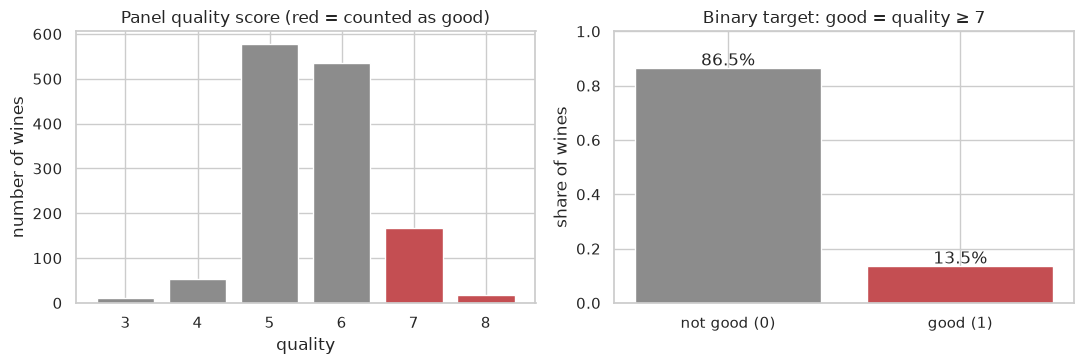

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

counts = df.quality.value_counts().sort_index()
colors = ['#c44e52' if q >= 7 else '#8c8c8c' for q in counts.index]
axes[0].bar(counts.index.astype(str), counts.values, color=colors)
axes[0].set_title('Panel quality score (red = counted as good)')
axes[0].set_xlabel('quality'); axes[0].set_ylabel('number of wines')

share = df.good.value_counts(normalize=True).sort_index()
axes[1].bar(['not good (0)', 'good (1)'], share.values, color=['#8c8c8c', '#c44e52'])
for i, v in enumerate(share.values):
    axes[1].text(i, v + 0.01, f'{v:.1%}', ha='center')
axes[1].set_title('Binary target: good = quality ≥ 7')
axes[1].set_ylabel('share of wines'); axes[1].set_ylim(0, 1)

plt.tight_layout()
save('target_distribution')
plt.show()

In [13]:
print(df.quality.value_counts().sort_index().to_dict())
print(f'share of good wines: {df.good.mean():.3f}')
print(f'accuracy of always predicting "not good": {1 - df.good.mean():.3f}')

{3: 10, 4: 53, 5: 577, 6: 535, 7: 167, 8: 17}
share of good wines: 0.135
accuracy of always predicting "not good": 0.865


Most wines score 5 or 6, and very few reach the extremes (3 or 8). Only about 13.5% are good, so a useless model that always says "not good" already scores ~86.5% accuracy. This is why we evaluate with ROC AUC and PR AUC rather than accuracy, and why every split below is **stratified** (it keeps the 13.5% share in every part).

### 3.3 Feature distributions by class

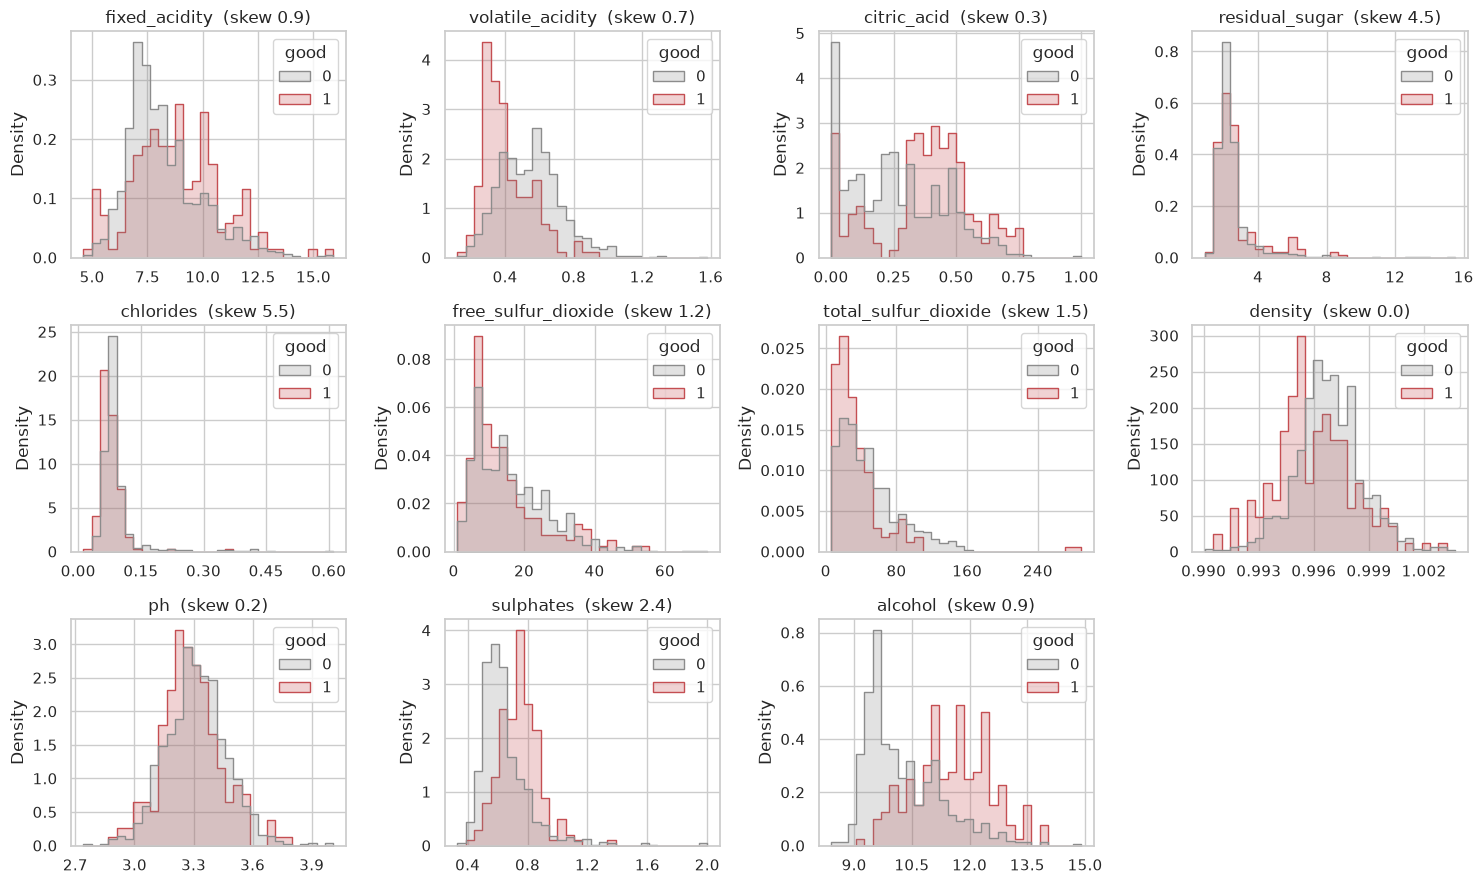

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue='good', stat='density', common_norm=False,
                 element='step', bins=30, ax=ax, palette=['#8c8c8c', '#c44e52'])
    ax.set_title(f'{col}  (skew {df[col].skew():.1f})')
    ax.set_xlabel('')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
axes.flat[-1].axis('off')
plt.tight_layout()
save('feature_distributions')
plt.show()

In [15]:
df[features].skew().sort_values(ascending=False).round(2)

chlorides               5.50
residual_sugar          4.55
sulphates               2.41
total_sulfur_dioxide    1.54
free_sulfur_dioxide     1.23
fixed_acidity           0.94
alcohol                 0.86
volatile_acidity        0.73
citric_acid             0.31
ph                      0.23
density                 0.04
dtype: float64

Each class is normalised separately (`common_norm=False`), so we compare *shapes*, not counts.

- **Strongly right-skewed:** `chlorides`, `residual_sugar`, `sulphates`, `total_sulfur_dioxide` and `free_sulfur_dioxide`. Most wines sit in a narrow band, with a long tail of extreme values. A linear model may benefit from `log1p` on these (we test that in §6). Tree models don't care, because they only use the order of values.
- **Visibly shifted between classes:** `alcohol` (good wines have more), `volatile_acidity` (good wines have less), plus `sulphates` and `citric_acid` (good wines have more).
- **Nearly identical for both classes:** `residual_sugar`, `ph` and `free_sulfur_dioxide`, so expect little signal from them.

### 3.4 Top features vs quality

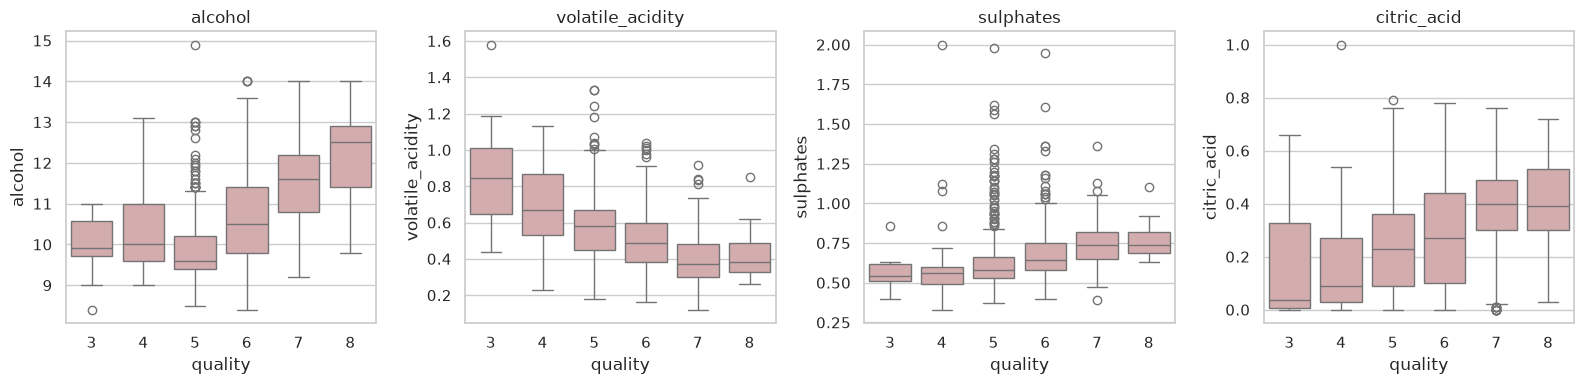

In [16]:
top = ['alcohol', 'volatile_acidity', 'sulphates', 'citric_acid']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top):
    sns.boxplot(data=df, x='quality', y=col, ax=ax, color='#d9a5a7')
    ax.set_title(col)
plt.tight_layout()
save('top_features_boxplots')
plt.show()

In [17]:
df.groupby('good')[top].median()

,alcohol,volatile_acidity,sulphates,citric_acid
good,,,,
0,10.0,0.54,0.60,0.24
1,11.6,0.37,0.74,0.40


The trends run across the whole scale, not just at the 7 cut-off. Median alcohol rises with quality, volatile acidity (vinegar-like acetic acid, a known fault) falls, and sulphates and citric acid rise. The boxes overlap a lot, though, so no single feature separates good from not-good wines by itself, and a model that combines them should help.

### 3.5 Correlation

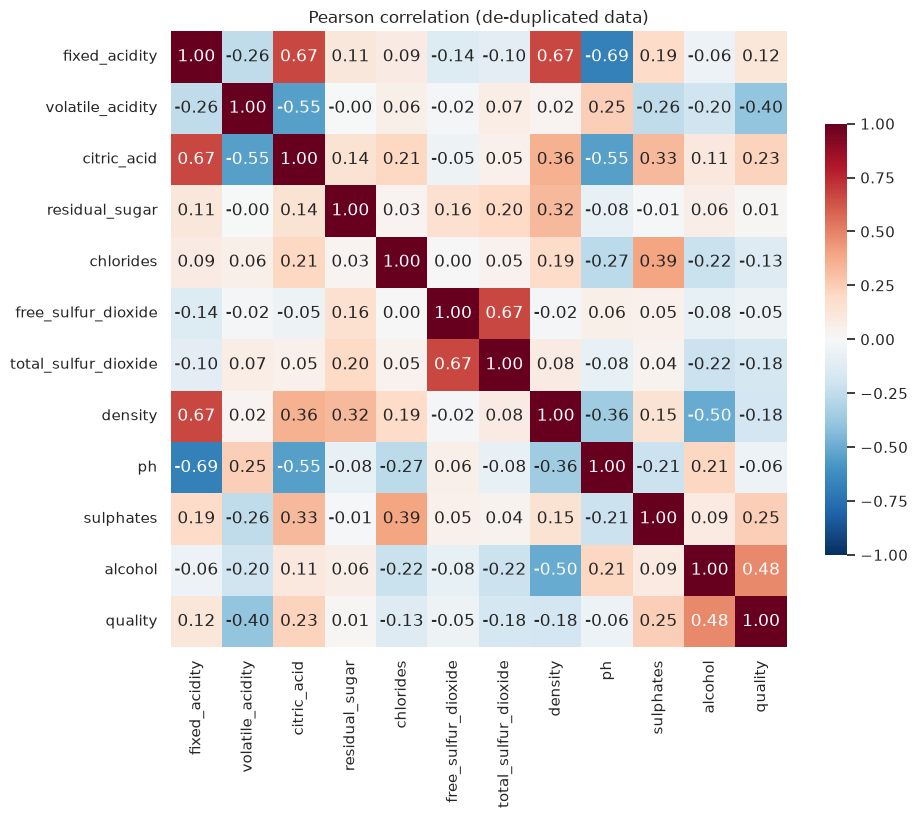

In [18]:
corr = df[features + ['quality']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            cbar_kws={'shrink': 0.7})
plt.title('Pearson correlation (de-duplicated data)')
save('correlation_heatmap')
plt.show()

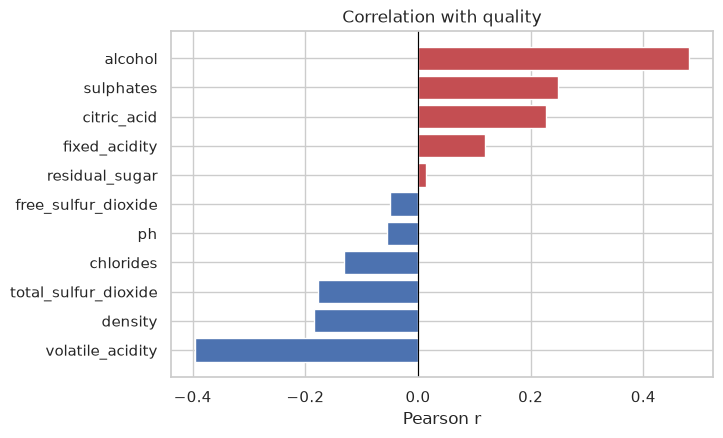

alcohol                 0.480
volatile_acidity       -0.395
sulphates               0.249
citric_acid             0.228
density                -0.184
total_sulfur_dioxide   -0.178
chlorides              -0.131
fixed_acidity           0.119
ph                     -0.055
free_sulfur_dioxide    -0.050
residual_sugar          0.014
Name: quality, dtype: float64

In [19]:
corr_q = corr['quality'].drop('quality').sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(corr_q.index, corr_q.values, color=['#c44e52' if v > 0 else '#4c72b0' for v in corr_q.values])
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlation with quality')
plt.xlabel('Pearson r')
save('correlation_with_quality')
plt.show()

corr_q.sort_values(key=abs, ascending=False).round(3)

In [20]:
# collinear feature pairs (|r| > 0.5)
pairs = (corr.loc[features, features]
         .where(np.triu(np.ones((len(features), len(features)), dtype=bool), k=1))
         .stack()
         .rename('r'))
pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(2)

fixed_acidity        ph                     -0.69
                     density                 0.67
                     citric_acid             0.67
free_sulfur_dioxide  total_sulfur_dioxide    0.67
volatile_acidity     citric_acid            -0.55
citric_acid          ph                     -0.55
density              alcohol                -0.50
Name: r, dtype: float64

- **Strongest linear relations with quality:** `alcohol` (positive) and `volatile_acidity` (negative), followed by `sulphates` and `citric_acid` (positive).
- **Collinear groups:**
  - the "acidity block": `fixed_acidity`, `citric_acid`, `density` and `ph` (more acid means lower pH);
  - `free_sulfur_dioxide` with `total_sulfur_dioxide` (the free part is included in the total);
  - `density` with `alcohol` (alcohol is lighter than water).

  Collinearity doesn't hurt predictions much, but it makes **logistic regression coefficients harder to interpret**: correlated features share credit. Regularisation (the `C` parameter) keeps them stable.

### 3.6 Mutual information with the target

Correlation only captures *linear* relations. **Mutual information** (MI) measures how much knowing a feature reduces uncertainty about `good`, including non-linear relations. 0 means the feature tells us nothing about the target.

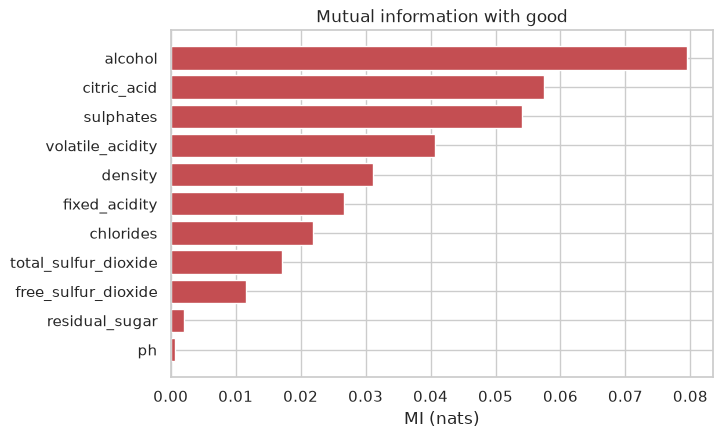

,mi,mi_rank,abs_corr_with_good,corr_rank
alcohol,0.0795,1,0.410,1
citric_acid,0.0574,2,0.204,3
sulphates,0.0541,3,0.202,4
volatile_acidity,0.0406,4,0.267,2
density,0.0311,5,0.158,5
fixed_acidity,0.0266,6,0.116,7
chlorides,0.0219,7,0.097,8
total_sulfur_dioxide,0.0171,8,0.136,6
free_sulfur_dioxide,0.0116,9,0.073,9
residual_sugar,0.0021,10,0.053,11


In [21]:
mi = pd.Series(mutual_info_classif(df[features], df.good, random_state=1), index=features)
mi = mi.sort_values(ascending=False)

plt.figure(figsize=(7, 4.5))
plt.barh(mi.index[::-1], mi.values[::-1], color='#c44e52')
plt.title('Mutual information with good')
plt.xlabel('MI (nats)')
save('mutual_information')
plt.show()

corr_good = df[features].corrwith(df.good)
pd.DataFrame({
    'mi': mi.round(4),
    'mi_rank': mi.rank(ascending=False).astype(int),
    'abs_corr_with_good': corr_good.abs().round(3),
    'corr_rank': corr_good.abs().rank(ascending=False).astype(int),
}).sort_values('mi_rank')

Both methods put the same four features at the top: **alcohol, citric_acid, sulphates and volatile_acidity**, though in a slightly different order. They also agree that `residual_sugar` and `ph` carry almost no information about `good`. We still keep every feature: there are only 11, and the tree models can pick up interactions that this one-feature-at-a-time view misses.

### 3.7 Outliers

We count values outside the usual box-plot fences, `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`, where IQR = Q3 − Q1.

In [22]:
q1 = df[features].quantile(0.25)
q3 = df[features].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)

outliers = pd.DataFrame({
    'n_outliers': is_outlier.sum(),
    'share': is_outlier.mean().round(3),
    'max': df[features].max(),
}).sort_values('n_outliers', ascending=False)
outliers

,n_outliers,share,max
residual_sugar,126,0.093,15.50000
chlorides,87,0.064,0.61100
sulphates,55,0.040,2.00000
total_sulfur_dioxide,45,0.033,289.00000
fixed_acidity,41,0.030,15.90000
density,35,0.026,1.00369
ph,28,0.021,4.01000
free_sulfur_dioxide,26,0.019,72.00000
volatile_acidity,19,0.014,1.58000
alcohol,12,0.009,14.90000


In [23]:
print(f'rows with at least one outlier: {is_outlier.any(axis=1).sum()} of {len(df)}')
print(f'share of good wines among those rows: {df.good[is_outlier.any(axis=1)].mean():.3f} '
      f'(overall {df.good.mean():.3f})')

rows with at least one outlier: 340 of 1359
share of good wines among those rows: 0.171 (overall 0.135)


**Decision: keep the outliers.**
- They are physically plausible (e.g. high sulphates or sugar), not data-entry errors.
- Dropping every row with an outlier would throw away a quarter of the data (340 of 1,359 rows).
- Those rows are *more* often good (~17% vs ~13.5% overall), so removing them would remove exactly the wines we want to find.
- The final API will receive such wines too.

Tree models (decision tree, random forest, XGBoost) only split on value order, so extremes don't distort them. For logistic regression we standardise features and test a `log1p` transform of the skewed ones (§6).

> **Takeaway (§3).** Only ~13.5% of wines are good, so accuracy is the wrong metric and every split must be stratified. Alcohol, volatile acidity, sulphates and citric acid carry most of the signal, by both correlation and mutual information; residual sugar and pH carry almost none. Several features are skewed, collinear or have outliers. That is no problem for trees, and for logistic regression we handle it with scaling and regularisation.

## 4. Validation framework

We follow the course pattern of a **60% / 20% / 20%** split into train, validation and test:
- **train:** fit models;
- **validation:** compare models and tune hyperparameters;
- **test:** touched **once**, at the very end (§12), to get an honest estimate for unseen batches.

We split in two steps: full_train/test 80/20, then full_train into train/val 75/25 (0.75 × 0.8 = 60%). `stratify` keeps the share of good wines the same in all three parts. Without it, a random split of such a small, imbalanced dataset could leave the validation set with noticeably more or fewer good wines, making scores noisy. `random_state=1` makes the split reproducible.

In [24]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df.good)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train.good)

for name, part in [('train', df_train), ('val', df_val), ('test', df_test), ('full_train', df_full_train)]:
    print(f'{name:10s} n={len(part):4d}  good={part.good.sum():3d}  share={part.good.mean():.3f}')

train      n= 815  good=110  share=0.135
val        n= 272  good= 37  share=0.136
test       n= 272  good= 37  share=0.136
full_train n=1087  good=147  share=0.135


In [25]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train.good.values
y_train = df_train.good.values
y_val = df_val.good.values
y_test = df_test.good.values

# features only: remove the target and its source column
for part in [df_full_train, df_train, df_val, df_test]:
    del part['good']
    del part['quality']

df_train.columns.tolist()

['fixed_acidity',
 'volatile_acidity',
 'citric_acid',
 'residual_sugar',
 'chlorides',
 'free_sulfur_dioxide',
 'total_sulfur_dioxide',
 'density',
 'ph',
 'sulphates',
 'alcohol']

> **Takeaway (§4).** The three parts have about 815 / 272 / 272 wines, each ~13.5% good. With only ~37 good wines in validation, small AUC differences between models are noisy. That is why §10 also compares the tuned models with 5-fold cross-validation on full_train. The test set stays untouched until the final model is chosen.